# Notebook 22a — Wu 2003: S-C Dataset Generation (S-B + Feed Analyzer)

## Purpose

Companion to `notebooks/22_wu2003_data_generation.ipynb`, adding the S-C (feed-analyzer)
observation view to the existing dataset. Per
`docs/Manuscript/system_ii_analyzer_rework_plan.md`'s bank-generation-efficiency note: since
the feed-analyzer reading is synthesized directly from each window's `z_A0_eff` (already
known at generation time), **this notebook does not re-run any ODE simulation** — it loads
`nb22`'s already-saved `data/wu2003_observations.npz` and augments it with the new channel,
an O(n_windows) operation, not a new ~5-10 minute simulation pass.

## Output file

`../data/wu2003_observations_sc.npz` — same contents as `wu2003_observations.npz`
(`observations_sa`, `observations_sb`, `labels`, `scenario_table`, ...) plus
`observations_sc` (10-channel: S-B's 9 + the feed-analyzer reading) and `sc_channels`.

In [1]:
import sys; sys.path.insert(0, '../src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pathlib

from cstr_sbi.recycle.simulator import load_dataset, save_dataset, generate_sc_observations
from cstr_sbi.recycle.summaries import SC_CHANNELS, FEED_ANALYZER_NOISE_PCT, Z_A0_EFF_PARAM_IDX

DATA = pathlib.Path('../data'); DATA.mkdir(exist_ok=True)
FIGURES = pathlib.Path('../figures'); FIGURES.mkdir(exist_ok=True)
OI = ["#000000","#E69F00","#56B4E9","#009E73","#F0E442","#0072B2","#D55E00","#CC79A7"]

SB_DATASET_PATH = DATA / 'wu2003_observations.npz'
assert SB_DATASET_PATH.exists(), f"{SB_DATASET_PATH} not found -- run nb22 first"
print(f"SC_CHANNELS ({len(SC_CHANNELS)}): {SC_CHANNELS}")
print(f"FEED_ANALYZER_NOISE_PCT = {FEED_ANALYZER_NOISE_PCT}")

SC_CHANNELS (10): ['T_r', 'T_j', 'Q_j', 'T_reb', 'Q_reb', 'F_R_norm', 'F_B_norm', 'R_norm', 'V_norm', 'feed_analyzer']
FEED_ANALYZER_NOISE_PCT = 0.0001


## Section 1 — Load nb22's S-B Dataset and Augment with the Feed-Analyzer Channel

In [2]:
dataset = load_dataset(SB_DATASET_PATH)
obs_sb = dataset['observations_sb']
labels = dataset['labels']
t_h = dataset['t_h']
print(f"Loaded {SB_DATASET_PATH.name}: observations_sb {obs_sb.shape}, {len(labels)} labeled windows")

import time
t0 = time.time()
obs_sc = generate_sc_observations(obs_sb, labels, t_h, seed=20260901)
print(f"Generated observations_sc {obs_sc.shape} in {time.time()-t0:.2f}s (no ODE re-simulation)")

assert obs_sc.shape == (obs_sb.shape[0], obs_sb.shape[1], obs_sb.shape[2] + 1)
assert not np.isnan(obs_sc).any(), "NaN in observations_sc"
print("Shape and NaN checks PASSED")

Loaded wu2003_observations.npz: observations_sb (420, 120, 9), 420 labeled windows
Generated observations_sc (420, 120, 10) in 0.00s (no ODE re-simulation)
Shape and NaN checks PASSED


## Section 2 — Feed-Analyzer Fidelity Check

Confirm the augmented channel actually reproduces each window's true `z_A0_eff` at the
settled `0.01%` noise level -- the same check as `nb20a`/`nb21a`, now against the full
420-window dataset (14 scenarios x 30 replicates) rather than a single deterministic
trajectory per scenario.

Max |feed_analyzer window-mean - true z_A0_eff| across 420 windows: 2.62e-05
PASSED
corr(true z_A0_eff, feed_analyzer window-mean) across all 420 windows = 1.000000


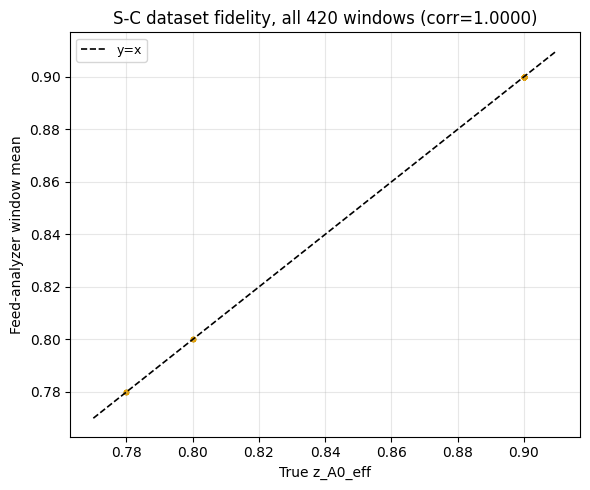

Saved 22a_feed_analyzer_fidelity.png


In [3]:
feed_col = obs_sc[:, :, -1]   # (n_windows, n_save)
feed_mean_per_window = feed_col.mean(axis=1)
true_z_a0 = labels['z_A0_eff'].to_numpy()

max_abs_err = np.max(np.abs(feed_mean_per_window - true_z_a0))
print(f"Max |feed_analyzer window-mean - true z_A0_eff| across {len(labels)} windows: {max_abs_err:.2e}")
assert max_abs_err < 0.01, "Feed-analyzer reading deviates too far from true z_A0_eff"
print("PASSED")

corr = np.corrcoef(true_z_a0, feed_mean_per_window)[0, 1]
print(f"corr(true z_A0_eff, feed_analyzer window-mean) across all {len(labels)} windows = {corr:.6f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(true_z_a0, feed_mean_per_window, s=8, alpha=0.4, color=OI[1])
lims = [true_z_a0.min() - 0.01, true_z_a0.max() + 0.01]
ax.plot(lims, lims, color=OI[0], ls='--', lw=1.2, label='y=x')
ax.set_xlabel('True z_A0_eff'); ax.set_ylabel('Feed-analyzer window mean')
ax.set_title(f'S-C dataset fidelity, all {len(labels)} windows (corr={corr:.4f})')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / '22a_feed_analyzer_fidelity.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved 22a_feed_analyzer_fidelity.png")

## Section 3 — Physical Effect Check: Feed-Analyzer Reading by Scenario

Mirrors `nb22` Section 4's `F_R_norm` bar chart, for the new channel.

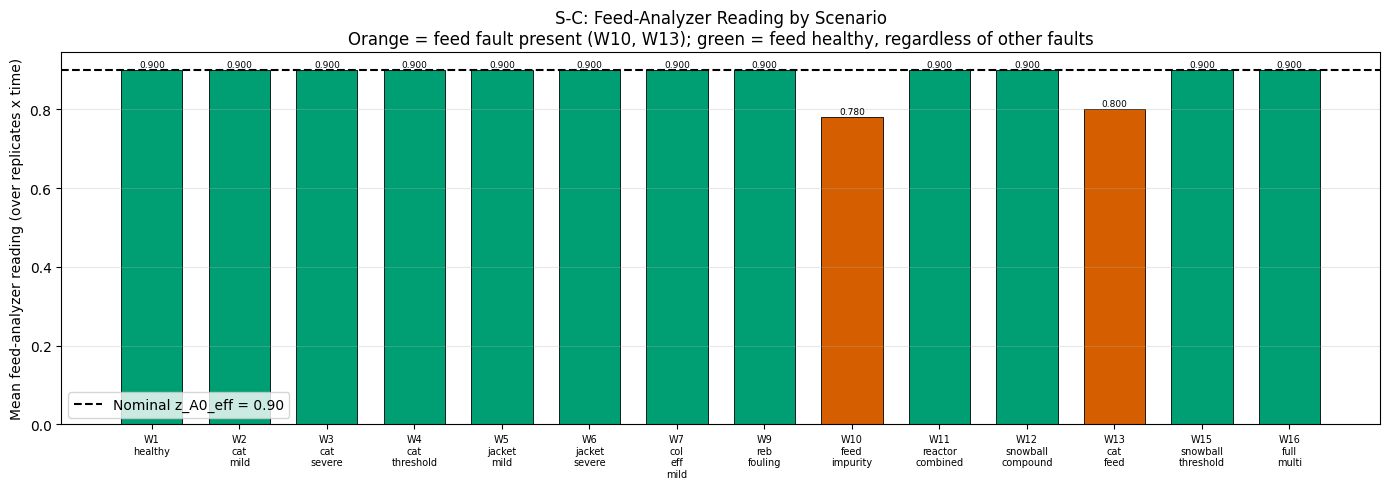

Feed-analyzer summary (mean +/- std over replicates and time):
  W1_healthy                    : 0.9000 +/- 0.0001
  W2_cat_mild                   : 0.9000 +/- 0.0001
  W3_cat_severe                 : 0.9000 +/- 0.0001
  W4_cat_threshold              : 0.9000 +/- 0.0001
  W5_jacket_mild                : 0.9000 +/- 0.0001
  W6_jacket_severe              : 0.9000 +/- 0.0001
  W7_col_eff_mild               : 0.9000 +/- 0.0001
  W9_reb_fouling                : 0.9000 +/- 0.0001
  W10_feed_impurity             : 0.7800 +/- 0.0001
  W11_reactor_combined          : 0.9000 +/- 0.0001
  W12_snowball_compound         : 0.9000 +/- 0.0001
  W13_cat_feed                  : 0.8000 +/- 0.0001
  W15_snowball_threshold        : 0.9000 +/- 0.0001
  W16_full_multi                : 0.9000 +/- 0.0001
Saved 22a_feed_analyzer_by_scenario.png


In [4]:
labels_4d_names = labels['scenario_name'].values
scenario_order = list(dict.fromkeys(labels_4d_names))  # preserves first-seen order (id-sorted)
n_sc = len(scenario_order)
n_rep = dataset['n_replicates']

obs_sc_4d = obs_sc.reshape(n_sc, n_rep, obs_sc.shape[1], obs_sc.shape[2])
mean_feed = obs_sc_4d[:, :, :, -1].mean(axis=(1, 2))
std_feed = obs_sc_4d[:, :, :, -1].std(axis=(1, 2))

fig, ax = plt.subplots(figsize=(14, 5))
bar_colors = [OI[3] if abs(v - 0.90) < 0.02 else OI[6] for v in mean_feed]
short_names = [n.replace('_', '\n') for n in scenario_order]
bars = ax.bar(range(n_sc), mean_feed, color=bar_colors, edgecolor='k', linewidth=0.6, width=0.7)
ax.axhline(0.90, color=OI[0], ls='--', lw=1.5, label='Nominal z_A0_eff = 0.90')
ax.set_xticks(range(n_sc)); ax.set_xticklabels(short_names, fontsize=7)
ax.set_ylabel('Mean feed-analyzer reading (over replicates x time)')
ax.set_title('S-C: Feed-Analyzer Reading by Scenario\n'
             'Orange = feed fault present (W10, W13); green = feed healthy, regardless of other faults')
ax.legend(fontsize=10)
ax.grid(True, axis='y', alpha=0.3)
for i, (bar, val) in enumerate(zip(bars, mean_feed)):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.002, f'{val:.3f}', ha='center', va='bottom', fontsize=6.5)
fig.tight_layout()
fig.savefig(FIGURES / '22a_feed_analyzer_by_scenario.png', dpi=150, bbox_inches='tight')
plt.show()

print("Feed-analyzer summary (mean +/- std over replicates and time):")
for name, mu, sig in zip(scenario_order, mean_feed, std_feed):
    print(f"  {name:30s}: {mu:.4f} +/- {sig:.4f}")
print("Saved 22a_feed_analyzer_by_scenario.png")

## Section 4 — Save S-C Dataset

In [5]:
dataset['observations_sc'] = obs_sc
dataset['sc_channels'] = SC_CHANNELS

save_path = DATA / 'wu2003_observations_sc.npz'
saved = save_dataset(dataset, save_path)
print(f"Saved to {saved}")
print(f"File size: {saved.stat().st_size / 1e6:.1f} MB")

Saved to ../data/wu2003_observations_sc.npz
File size: 10.7 MB


## Section 5 — Load Round-Trip Verification

In [6]:
dataset2 = load_dataset(save_path)
assert np.allclose(dataset2['observations_sc'], dataset['observations_sc']), "observations_sc round-trip mismatch"
assert np.allclose(dataset2['observations_sb'], dataset['observations_sb']), "observations_sb round-trip mismatch"
assert dataset2['sc_channels'] == SC_CHANNELS
print("Round-trip load verified")
print(f"obs_sc shape: {dataset2['observations_sc'].shape}")
print(f"sc_channels: {dataset2['sc_channels']}")
print()
print("=== Notebook 22a complete ===")
print(f"Dataset saved at: {save_path}")

Round-trip load verified
obs_sc shape: (420, 120, 10)
sc_channels: ['T_r', 'T_j', 'Q_j', 'T_reb', 'Q_reb', 'F_R_norm', 'F_B_norm', 'R_norm', 'V_norm', 'feed_analyzer']

=== Notebook 22a complete ===
Dataset saved at: ../data/wu2003_observations_sc.npz


### S-C dataset generation complete

Ready for:
- **nb23a:** Summary statistics computation (feature table, PCA, mutual information,
  corrected-methodology FIM comparison against S-B)
- **Phase 2 of `system_ii_analyzer_rework_plan.md`:** paired S-B/S-C SNPE training bank
  generation and SBI retraining